In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load historical monthly exchange-rate data
df = pd.read_csv("../data/raw/inr_usd_fred_1973_2024.csv")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date").asfreq("MS")

# Display data range and latest observations
print("Data start:", df.index.min())
print("Data end:", df.index.max())
print(df.tail())

Data start: 1973-01-01 00:00:00
Data end: 2024-08-01 00:00:00
            INR_per_USD
Date                   
2024-04-01      83.3968
2024-05-01      83.3873
2024-06-01      83.4600
2024-07-01      83.5895
2024-08-01      83.8855


Missing values: 0
Duplicate dates: 0
Number of observations: 620


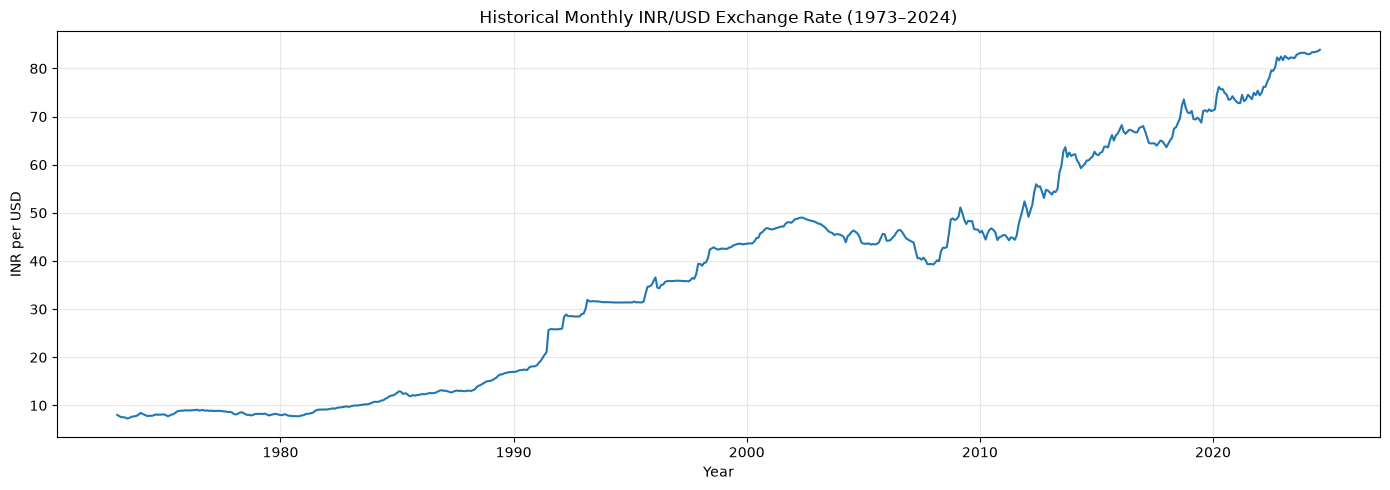

In [3]:
# Check missing values
print("Missing values:", df["INR_per_USD"].isna().sum())

# Check duplicate dates
print("Duplicate dates:", df.index.duplicated().sum())

# Monthly frequency check
print("Number of observations:", len(df))

# Plot historical data
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["INR_per_USD"])
plt.title("Historical Monthly INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Train-test split (80% training, 20% testing)

split_index = int(len(df) * 0.80)

train = df["INR_per_USD"].iloc[:split_index]
test = df["INR_per_USD"].iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 496
Testing observations: 124
Training period: 1973-01-01 00:00:00 to 2014-04-01 00:00:00
Testing period: 2014-05-01 00:00:00 to 2024-08-01 00:00:00


In [5]:
from statsmodels.tsa.arima.model import ARIMA

# Train ARIMA model
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

# Forecast the testing period
predictions = model_fit.forecast(steps=len(test))
predictions.index = test.index

print("ARIMA model trained successfully!")
print(predictions.head())

ARIMA model trained successfully!
Date
2014-05-01    60.295915
2014-06-01    60.299589
2014-07-01    60.299322
2014-08-01    60.299341
2014-09-01    60.299340
Freq: MS, Name: predicted_mean, dtype: float64


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))
mape = np.mean(np.abs((test - predictions) / test)) * 100

print("ARIMA Model Evaluation")
print("----------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("MAPE:", round(mape, 2), "%")

ARIMA Model Evaluation
----------------------
MAE: 11.389
RMSE: 13.342
MAPE: 15.11 %


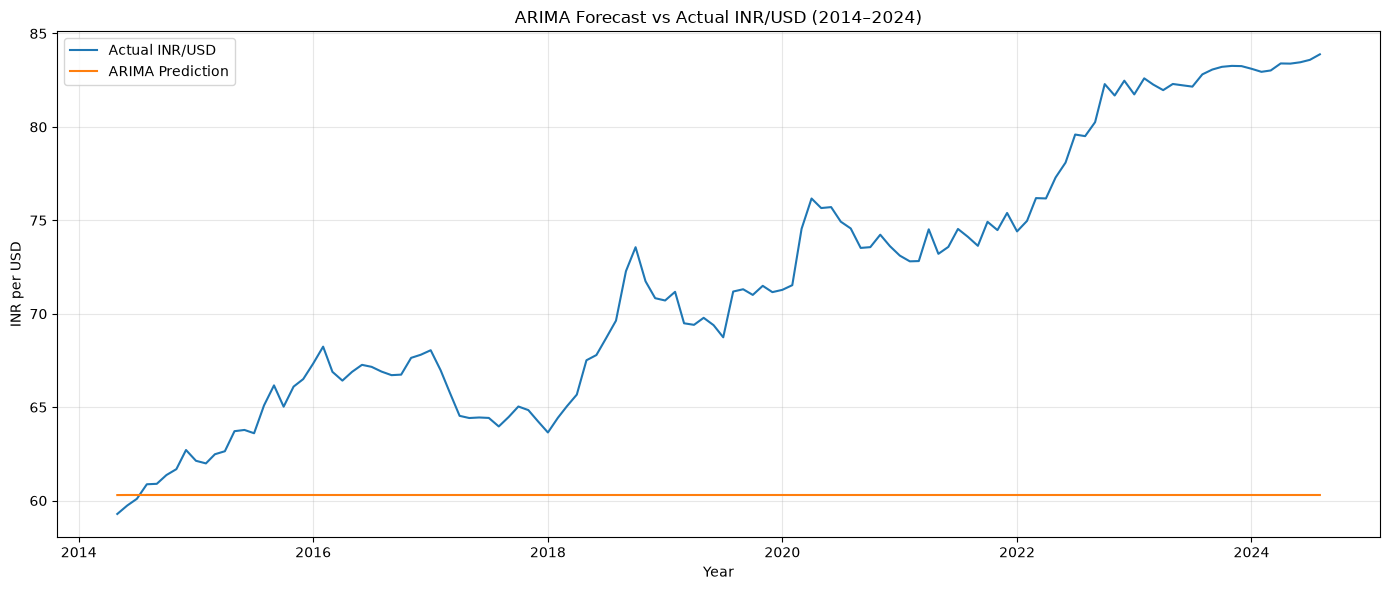

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual INR/USD")
plt.plot(predictions.index, predictions, label="ARIMA Prediction")

plt.title("ARIMA Forecast vs Actual INR/USD (2014–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\arima_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Train Holt's trend model
holt_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal=None
)

holt_fit = holt_model.fit(optimized=True)

# Forecast the test period
holt_predictions = holt_fit.forecast(len(test))
holt_predictions.index = test.index

# Evaluate
holt_mae = mean_absolute_error(test, holt_predictions)
holt_rmse = np.sqrt(mean_squared_error(test, holt_predictions))
holt_mape = np.mean(np.abs((test - holt_predictions) / test)) * 100

print("Holt's Exponential Smoothing Evaluation")
print("MAE:", round(holt_mae, 3))
print("RMSE:", round(holt_rmse, 3))
print("MAPE:", round(holt_mape, 2), "%")

Holt's Exponential Smoothing Evaluation
MAE: 12.508
RMSE: 14.348
MAPE: 16.67 %


In [9]:
from sklearn.linear_model import LinearRegression

# Convert dates into numeric time steps
X_train = np.arange(len(train)).reshape(-1, 1)
X_test = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)

# Train on log exchange rates
log_model = LinearRegression()
log_model.fit(X_train, np.log(train.values))

# Predict and convert back to exchange-rate levels
log_predictions = np.exp(log_model.predict(X_test))
log_predictions = pd.Series(log_predictions, index=test.index)

# Evaluate
log_mae = mean_absolute_error(test, log_predictions)
log_rmse = np.sqrt(mean_squared_error(test, log_predictions))
log_mape = np.mean(np.abs((test - log_predictions) / test)) * 100

print("Log-Linear Regression Evaluation")
print("MAE:", round(log_mae, 3))
print("RMSE:", round(log_rmse, 3))
print("MAPE:", round(log_mape, 2), "%")

Log-Linear Regression Evaluation
MAE: 31.298
RMSE: 33.266
MAPE: 42.71 %


In [10]:
# Train ARIMA(2,1,2)
model_212 = ARIMA(train, order=(2, 1, 2))
fit_212 = model_212.fit()

# Forecast test period
pred_212 = fit_212.forecast(steps=len(test))
pred_212.index = test.index

# Evaluate
mae_212 = mean_absolute_error(test, pred_212)
rmse_212 = np.sqrt(mean_squared_error(test, pred_212))
mape_212 = np.mean(np.abs((test - pred_212) / test)) * 100

print("ARIMA(2,1,2) Evaluation")
print("MAE:", round(mae_212, 3))
print("RMSE:", round(rmse_212, 3))
print("MAPE:", round(mape_212, 2), "%")

C:\Users\Skyly\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Skyly\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA(2,1,2) Evaluation
MAE: 11.684
RMSE: 13.609
MAPE: 15.52 %


In [11]:
print("Frequency:", df.index.freq)
print("Missing values:", df["INR_per_USD"].isna().sum())

Frequency: <MonthBegin>
Missing values: 0


In [12]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_predictions = sarima_fit.forecast(steps=len(test))
sarima_predictions.index = test.index

sarima_mae = mean_absolute_error(test, sarima_predictions)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_predictions))
sarima_mape = np.mean(
    np.abs((test - sarima_predictions) / test)
) * 100

print("SARIMA Evaluation")
print("MAE:", round(sarima_mae, 3))
print("RMSE:", round(sarima_rmse, 3))
print("MAPE:", round(sarima_mape, 2), "%")

SARIMA Evaluation
MAE: 2.188
RMSE: 2.823
MAPE: 2.94 %


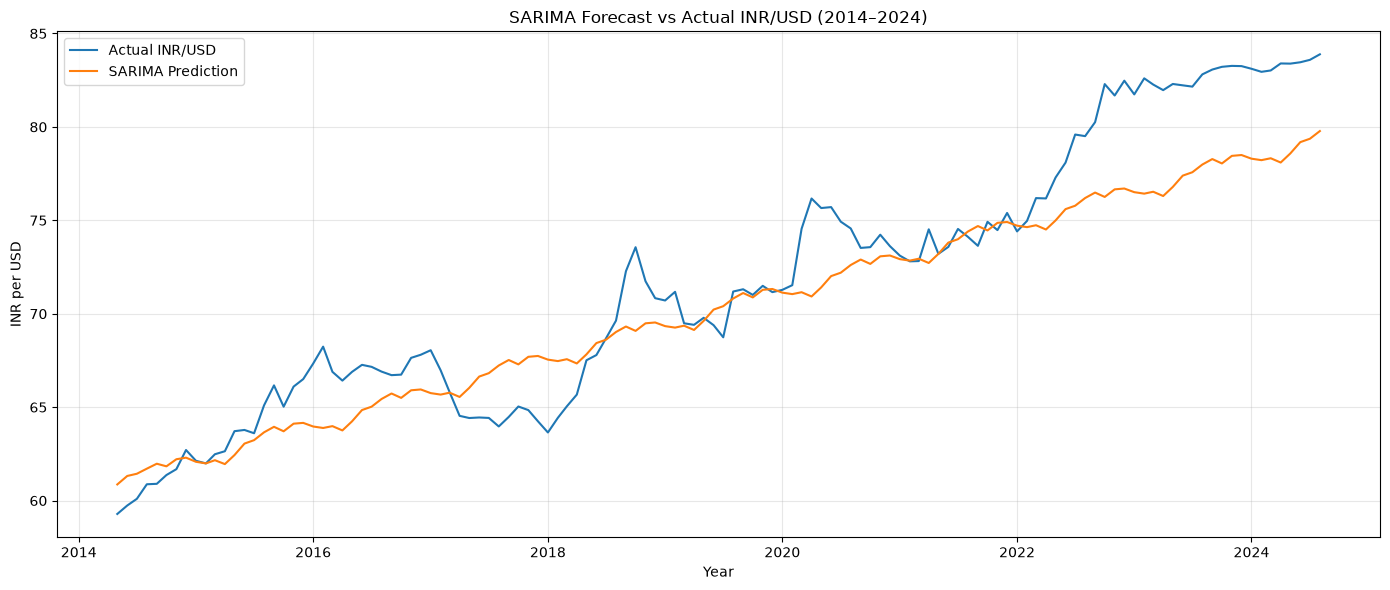

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual INR/USD")
plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Prediction"
)

plt.title("SARIMA Forecast vs Actual INR/USD (2014–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\sarima_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Validation using the final 24 months
validation = df["INR_per_USD"].iloc[-24:]
validation_train = df["INR_per_USD"].iloc[:-24]

validation_model = SARIMAX(
    validation_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

validation_fit = validation_model.fit(disp=False)

validation_predictions = validation_fit.forecast(
    steps=len(validation)
)

validation_mae = mean_absolute_error(
    validation, validation_predictions
)
validation_rmse = np.sqrt(
    mean_squared_error(validation, validation_predictions)
)
validation_mape = np.mean(
    np.abs((validation - validation_predictions) / validation)
) * 100

print("Final 24-month validation")
print("MAE:", round(validation_mae, 3))
print("RMSE:", round(validation_rmse, 3))
print("MAPE:", round(validation_mape, 2), "%")

Final 24-month validation
MAE: 2.112
RMSE: 2.152
MAPE: 2.55 %


In [15]:
# Fit SARIMA using all available historical data

final_model = SARIMAX(
    df["INR_per_USD"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fit = final_model.fit(disp=False)

# Forecast September 2024 to August 2050
future_steps = 312

future_forecast = final_fit.get_forecast(
    steps=future_steps
)

forecast_mean = future_forecast.predicted_mean
forecast_ci = future_forecast.conf_int()

# Keep September 2026 to August 2050
forecast_mean = forecast_mean.loc["2026-09-01":"2050-08-01"]
forecast_ci = forecast_ci.loc["2026-09-01":"2050-08-01"]

print("Forecast start:", forecast_mean.index.min())
print("Forecast end:", forecast_mean.index.max())
print("Number of forecast months:", len(forecast_mean))
print(forecast_mean.head())
print(forecast_mean.tail())

Forecast start: 2026-09-01 00:00:00
Forecast end: 2050-08-01 00:00:00
Number of forecast months: 288
2026-09-01    87.069796
2026-10-01    87.133634
2026-11-01    87.277516
2026-12-01    87.351887
2027-01-01    87.269379
Freq: MS, Name: predicted_mean, dtype: float64
2050-04-01    121.249135
2050-05-01    121.460514
2050-06-01    121.715385
2050-07-01    121.893911
2050-08-01    122.136606
Freq: MS, Name: predicted_mean, dtype: float64


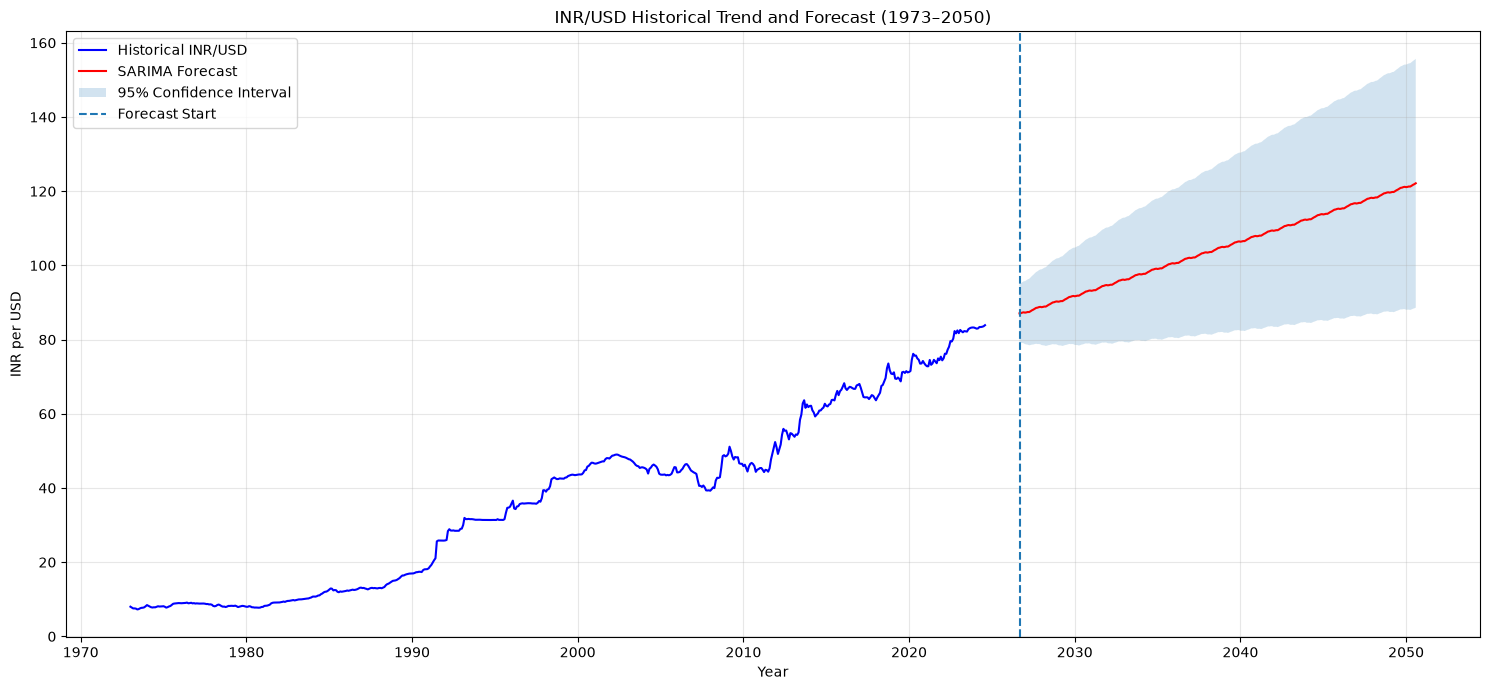

In [16]:
plt.figure(figsize=(15, 7))

# Historical exchange rate
plt.plot(
    df.index,
    df["INR_per_USD"],
    label="Historical INR/USD",
    color="blue"
)

# Forecast
plt.plot(
    forecast_mean.index,
    forecast_mean,
    label="SARIMA Forecast",
    color="red"
)

# Confidence interval
plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

# Mark forecast start
plt.axvline(
    pd.Timestamp("2026-09-01"),
    linestyle="--",
    label="Forecast Start"
)

plt.title("INR/USD Historical Trend and Forecast (1973–2050)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\inr_usd_forecast_2026_2050.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Create forecast results table

forecast_results = pd.DataFrame({
    "Forecast_INR_per_USD": forecast_mean,
    "Lower_95_CI": forecast_ci.iloc[:, 0],
    "Upper_95_CI": forecast_ci.iloc[:, 1]
})

forecast_results.index.name = "Date"

output_path = (
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis"
    r"\data\processed\inr_usd_forecast_2026_2050.csv"
)

forecast_results.to_csv(output_path)

print("Forecast CSV saved successfully!")
print(forecast_results.head())
print(forecast_results.tail())

Forecast CSV saved successfully!
            Forecast_INR_per_USD  Lower_95_CI  Upper_95_CI
Date                                                      
2026-09-01             87.069796    79.212223    94.927369
2026-10-01             87.133634    79.110083    95.157186
2026-11-01             87.277516    79.091551    95.463481
2026-12-01             87.351887    79.006636    95.697138
2027-01-01             87.269379    78.767831    95.770927
            Forecast_INR_per_USD  Lower_95_CI  Upper_95_CI
Date                                                      
2050-04-01            121.249135    87.998596   154.499674
2050-05-01            121.460514    88.138627   154.782401
2050-06-01            121.715385    88.322300   155.108469
2050-07-01            121.893911    88.429781   155.358042
2050-08-01            122.136606    88.601580   155.671632


In [18]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis"
)

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

forecast_results.to_csv(
    processed_dir / "inr_usd_forecast_2026_2050.csv",
    index=True
)

print("Forecast CSV saved successfully!")
print("Rows:", len(forecast_results))

Forecast CSV saved successfully!
Rows: 288
